# Notebook 03: Sales and Commercial Performance

## Project: Retail Sales Intelligence

### 1. Introduction

This notebook evaluates the commercial performance of the retailer using the integrated analytical dataset prepared in Notebook 02.

The analysis focuses on translating transaction-level data into measurable business performance indicators.

It examines revenue generation, sales growth, product profitability, store performance and customer value.

### Objectives

1. Evaluate overall retail sales performance.
2. Measure monthly revenue growth and commercial trends.
3. Assess revenue and gross profit contribution by product category.
4. Identify high-performing and underperforming products.
5. Compare commercial performance across retail stores.
6. Evaluate customer purchasing behaviour and value.
7. Segment customers using Recency, Frequency and Monetary (RFM) analysis.
8. Develop performance benchmarks and management scorecards.
9. Generate analytical outputs for business recommendations and Power BI.

### Business Focus

The analysis aims to answer practical management questions:

- Is the retailer growing or experiencing declining sales?
- Which products and categories generate the greatest commercial value?
- Which stores perform best and which require attention?
- Which customers contribute most to revenue?
- How is profitability distributed across the business?
- Which customer segments present opportunities for retention and growth?

The findings will support evidence-based commercial decision-making.

## 2. Import Libraries and Configure Project Paths

Import the Python libraries required for commercial performance analysis.

The notebook uses Pandas and NumPy for data manipulation and calculations, Matplotlib for visualisation, and pathlib for project directory management.

The integrated dataset generated in Notebook 02 will serve as the primary analytical source.

In [44]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

# Configure Pandas display
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Configure project paths
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"

EDA_OUTPUT_DIR = PROCESSED_DIR / "eda_outputs"

COMMERCIAL_OUTPUT_DIR = (
    PROCESSED_DIR / "commercial_outputs"
)

COMMERCIAL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project directory:", PROJECT_DIR.resolve())
print("EDA output directory:", EDA_OUTPUT_DIR.resolve())
print("Commercial output directory:", COMMERCIAL_OUTPUT_DIR.resolve())

Project directory: C:\Users\Administrator\retail-sales-intelligence
EDA output directory: C:\Users\Administrator\retail-sales-intelligence\data\processed\eda_outputs
Commercial output directory: C:\Users\Administrator\retail-sales-intelligence\data\processed\commercial_outputs


## 3. Load Integrated Analytical Dataset

Load the enriched transaction-level dataset exported from Notebook 02.

The dataset contains sales transactions enriched with product, customer and store information, alongside calculated financial metrics.

The analysis uses the following commercial variables:

- Revenue.
- Product cost.
- Gross profit.
- Gross profit margin.
- Transaction quantity.
- Order date.
- Customer and product identifiers.
- Store identifiers.

Using the validated integrated dataset ensures consistency between the exploratory analysis and subsequent commercial performance analysis.

In [45]:
# Load integrated sales dataset

sales_file = EDA_OUTPUT_DIR / "sales_enriched_eda.csv"

if not sales_file.exists():
    raise FileNotFoundError(
        "Integrated dataset not found. "
        "Run Notebook 02 and confirm that "
        "sales_enriched_eda.csv was exported."
    )

sales = pd.read_csv(sales_file)

print("Integrated dataset loaded successfully.")
print("Dataset dimensions:", sales.shape)

display(sales.head())

Integrated dataset loaded successfully.
Dataset dimensions: (62884, 35)


,order_number,line_item,order_date,delivery_date,customer_key,store_key,product_key,quantity,currency_code,product_name,brand,color,unit_cost_usd,unit_price_usd,subcategory_key,subcategory,category_key,category,gender,name,city,state_code,state_x,zip_code,country_x,continent,birthday,country_y,state_y,square_meters,open_date,revenue_usd,product_cost_usd,gross_profit_usd,gross_profit_margin
0,366000,1,2016-01-01,NaN,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,Contoso,White,31.27,68.00,406,Cameras & Camcorders Accessories,4,Cameras and camcorders,Male,Tyler Vaught,London,ON,Ontario,N5W 5K6,Canada,North America,1971-03-23,Canada,Nunavut,"1,210.00",2015-04-04,68.00,31.27,36.73,54.01
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,A. Datum,Silver,141.47,427.00,402,Digital SLR Cameras,4,Cameras and camcorders,Male,Frank Upchurch,Auberry,CA,California,93602,United States,North America,1995-11-20,Online,Online,NaN,2010-01-01,854.00,282.94,571.06,66.87
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,Fabrikam,Black,220.64,665.94,803,Microwaves,8,Home Appliances,Male,Frank Upchurch,Auberry,CA,California,93602,United States,North America,1995-11-20,Online,Online,NaN,2010-01-01,665.94,220.64,445.30,66.87
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,Contoso,Orange,148.08,322.00,402,Digital SLR Cameras,4,Cameras and camcorders,Female,Joan Roche,Red Deer,AB,Alberta,T4N 2A6,Canada,North America,1962-08-24,Online,Online,NaN,2010-01-01,"2,254.00","1,036.56","1,217.44",54.01
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,Adventure Works,White,166.20,326.00,301,Laptops,3,Computers,Female,Joan Roche,Red Deer,AB,Alberta,T4N 2A6,Canada,North America,1962-08-24,Online,Online,NaN,2010-01-01,326.00,166.20,159.80,49.02


## 4. Data Validation

Before conducting commercial performance analysis, verify the integrity of the integrated dataset.

The validation examines:

- Required analytical columns.
- Missing financial observations.
- Duplicate transaction records.
- Date validity.
- Numeric data types.
- Financial calculation consistency.

This stage ensures that commercial performance indicators are calculated using reliable data.

Missing values will be investigated rather than automatically replaced with zero.

In [46]:
# Verify required columns

required_columns = [
    "order_date",
    "order_number",
    "product_key",
    "customer_key",
    "store_key",
    "quantity",
    "unit_price_usd",
    "unit_cost_usd",
    "revenue_usd",
    "product_cost_usd",
    "gross_profit_usd",
    "gross_profit_margin"
]

missing_columns = [
    col for col in required_columns
    if col not in sales.columns
]

if missing_columns:
    raise KeyError(
        f"Required columns missing: {missing_columns}"
    )

print("All required analytical columns are available.")

All required analytical columns are available.


In [47]:
# Convert analytical columns to appropriate data types

date_columns = ["order_date"]

numeric_columns = [
    "quantity",
    "unit_price_usd",
    "unit_cost_usd",
    "revenue_usd",
    "product_cost_usd",
    "gross_profit_usd",
    "gross_profit_margin"
]

for col in date_columns:
    sales[col] = pd.to_datetime(
        sales[col],
        errors="coerce"
    )

for col in numeric_columns:
    sales[col] = pd.to_numeric(
        sales[col],
        errors="coerce"
    )

# Inspect missing values
validation_summary = pd.DataFrame({
    "Column": required_columns,
    "Missing Values": [
        sales[col].isna().sum()
        for col in required_columns
    ],
    "Data Type": [
        str(sales[col].dtype)
        for col in required_columns
    ]
})

display(validation_summary)

,Column,Missing Values,Data Type
0,order_date,0,datetime64[ns]
1,order_number,0,int64
2,product_key,0,int64
3,customer_key,0,int64
4,store_key,0,int64
5,quantity,0,int64
6,unit_price_usd,0,float64
7,unit_cost_usd,0,float64
8,revenue_usd,0,float64
9,product_cost_usd,0,float64


In [48]:
# Validate financial calculations

revenue_check = np.isclose(
    sales["revenue_usd"],
    sales["quantity"] * sales["unit_price_usd"],
    equal_nan=True
)

cost_check = np.isclose(
    sales["product_cost_usd"],
    sales["quantity"] * sales["unit_cost_usd"],
    equal_nan=True
)

profit_check = np.isclose(
    sales["gross_profit_usd"],
    sales["revenue_usd"] - sales["product_cost_usd"],
    equal_nan=True
)

print("Revenue calculations passed:", revenue_check.sum())
print("Product cost calculations passed:", cost_check.sum())
print("Gross profit calculations passed:", profit_check.sum())

print("\nDuplicate transaction rows:", sales.duplicated().sum())

print("Invalid dates:", sales["order_date"].isna().sum())

Revenue calculations passed: 62884
Product cost calculations passed: 62884
Gross profit calculations passed: 62884

Duplicate transaction rows: 0
Invalid dates: 0


## 5. Executive Commercial Performance Indicators

Develop a high-level overview of the retailer's commercial performance using key performance indicators.

The indicators include:

- Total revenue.
- Total gross profit.
- Gross profit margin.
- Total product costs.
- Total orders.
- Total units sold.
- Average order value.
- Average selling price.
- Average revenue per customer.

These indicators provide management with an overview of the retailer's financial performance and sales activity.

Gross profit margin is calculated using total gross profit divided by total revenue rather than averaging individual transaction margins.

In [49]:
# Calculate executive commercial KPIs

total_revenue = sales["revenue_usd"].sum()

total_cost = sales["product_cost_usd"].sum()

total_gross_profit = sales["gross_profit_usd"].sum()

total_orders = sales["order_number"].nunique()

total_units = sales["quantity"].sum()

total_customers = sales["customer_key"].nunique()

gross_profit_margin = (
    total_gross_profit / total_revenue * 100
    if total_revenue != 0 else np.nan
)

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0 else np.nan
)

average_selling_price = (
    total_revenue / total_units
    if total_units > 0 else np.nan
)

average_revenue_per_customer = (
    total_revenue / total_customers
    if total_customers > 0 else np.nan
)


executive_kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue (USD)",
        "Total Product Cost (USD)",
        "Total Gross Profit (USD)",
        "Gross Profit Margin (%)",
        "Total Orders",
        "Total Units Sold",
        "Total Customers",
        "Average Order Value (USD)",
        "Average Selling Price (USD)",
        "Average Revenue per Customer (USD)"
    ],

    "Value": [
        total_revenue,
        total_cost,
        total_gross_profit,
        gross_profit_margin,
        total_orders,
        total_units,
        total_customers,
        average_order_value,
        average_selling_price,
        average_revenue_per_customer
    ]
})

display(executive_kpis)

,KPI,Value
0,Total Revenue (USD),"55,755,479.59"
1,Total Product Cost (USD),"23,092,791.21"
2,Total Gross Profit (USD),"32,662,688.38"
3,Gross Profit Margin (%),58.58
4,Total Orders,"26,326.00"
5,Total Units Sold,"197,757.00"
6,Total Customers,"11,887.00"
7,Average Order Value (USD),"2,117.89"
8,Average Selling Price (USD),281.94
9,Average Revenue per Customer (USD),"4,690.46"


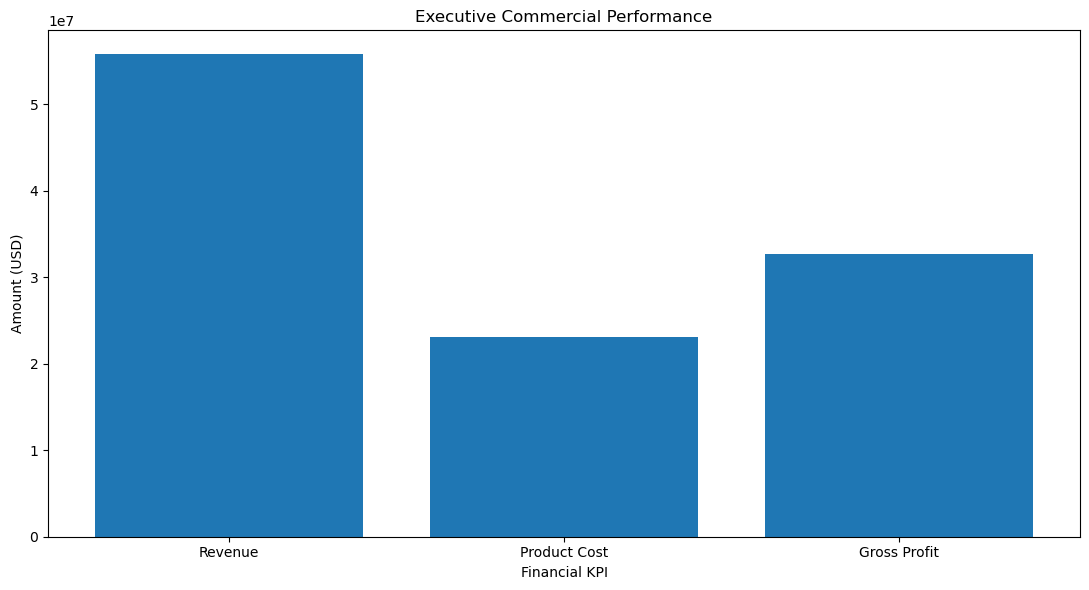

In [50]:
# Visualise executive financial KPIs

kpi_labels = [
    "Revenue",
    "Product Cost",
    "Gross Profit"
]

kpi_values = [
    total_revenue,
    total_cost,
    total_gross_profit
]

plt.figure(figsize=(11, 6))

plt.bar(kpi_labels, kpi_values)

plt.title("Executive Commercial Performance")
plt.ylabel("Amount (USD)")
plt.xlabel("Financial KPI")

plt.tight_layout()
plt.show()

## 6. Monthly Sales Growth Analysis

Evaluate the retailer's revenue performance over time.

Monthly revenue is aggregated to identify changes in commercial activity.

The analysis calculates:

- Monthly revenue.
- Month-on-month revenue change.
- Month-on-month revenue growth percentage.
- Monthly gross profit.
- Monthly gross profit margin.
- Monthly order volumes.

Month-on-month growth measures the percentage change in revenue compared with the preceding month.

A positive growth rate indicates an increase in revenue, while a negative rate indicates a decline.

The first month will have no previous month for comparison.

In [52]:
# Create monthly commercial performance dataset

sales["year_month"] = (
    sales["order_date"].dt.to_period("M")
)

monthly_performance = (
    sales.dropna(subset=["order_date"])
    .groupby("year_month")
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        product_cost_usd=("product_cost_usd", "sum"),
        orders=("order_number", "nunique"),
        units_sold=("quantity", "sum"),
        customers=("customer_key", "nunique")
    )
    .reset_index()
)

monthly_performance = monthly_performance.sort_values(
    "year_month"
)

monthly_performance["gross_profit_margin"] = np.where(
    monthly_performance["revenue_usd"] != 0,
    monthly_performance["gross_profit_usd"] /
    monthly_performance["revenue_usd"] * 100,
    np.nan
)

monthly_performance["revenue_change"] = (
    monthly_performance["revenue_usd"].diff()
)

monthly_performance["mom_growth_pct"] = (
    monthly_performance["revenue_usd"].pct_change() * 100
)

monthly_performance["year_month"] = (
    monthly_performance["year_month"].astype(str)
)

display(monthly_performance)

,year_month,revenue_usd,gross_profit_usd,product_cost_usd,orders,units_sold,customers,gross_profit_margin,revenue_change,mom_growth_pct
0,2016-01,"649,918.78","388,268.96","261,649.82",292,2116,289,59.74,NaN,NaN
1,2016-02,"891,098.30","531,722.75","359,375.55",334,2676,327,59.67,"241,179.52",37.11
2,2016-03,"338,407.36","203,506.99","134,900.37",109,895,109,60.14,"-552,690.94",-62.02
3,2016-04,"110,591.63","66,231.19","44,360.44",41,326,41,59.89,"-227,815.73",-67.32
4,2016-05,"595,986.18","356,049.32","239,936.86",220,1646,219,59.74,"485,394.55",438.91
5,2016-06,"518,585.28","294,270.49","224,314.79",243,1864,240,56.74,"-77,400.90",-12.99
6,2016-07,"454,959.83","269,369.43","185,590.40",201,1572,200,59.21,"-63,625.45",-12.27
7,2016-08,"547,512.69","325,909.91","221,602.78",229,1611,226,59.53,"92,552.86",20.34
8,2016-09,"567,421.12","331,859.55","235,561.57",262,1885,262,58.49,"19,908.43",3.64
9,2016-10,"623,959.57","365,597.98","258,361.59",258,2042,256,58.59,"56,538.45",9.96


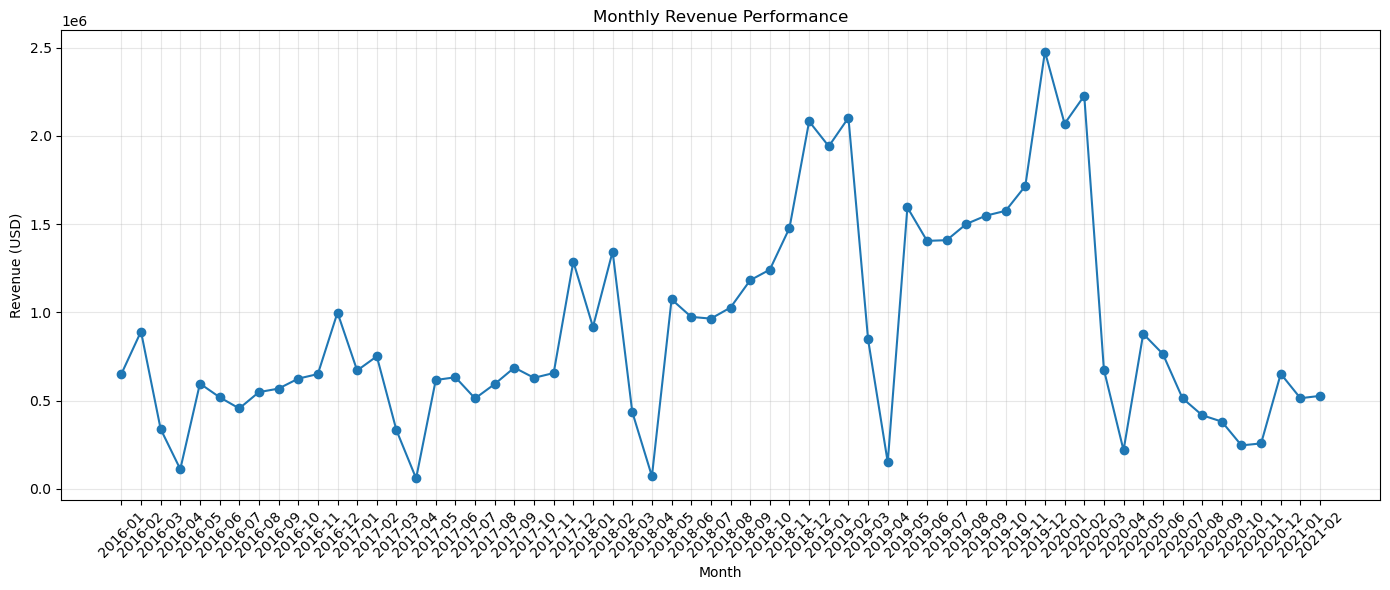

In [53]:
# Visualise monthly revenue performance

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance["year_month"],
    monthly_performance["revenue_usd"],
    marker="o"
)

plt.title("Monthly Revenue Performance")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

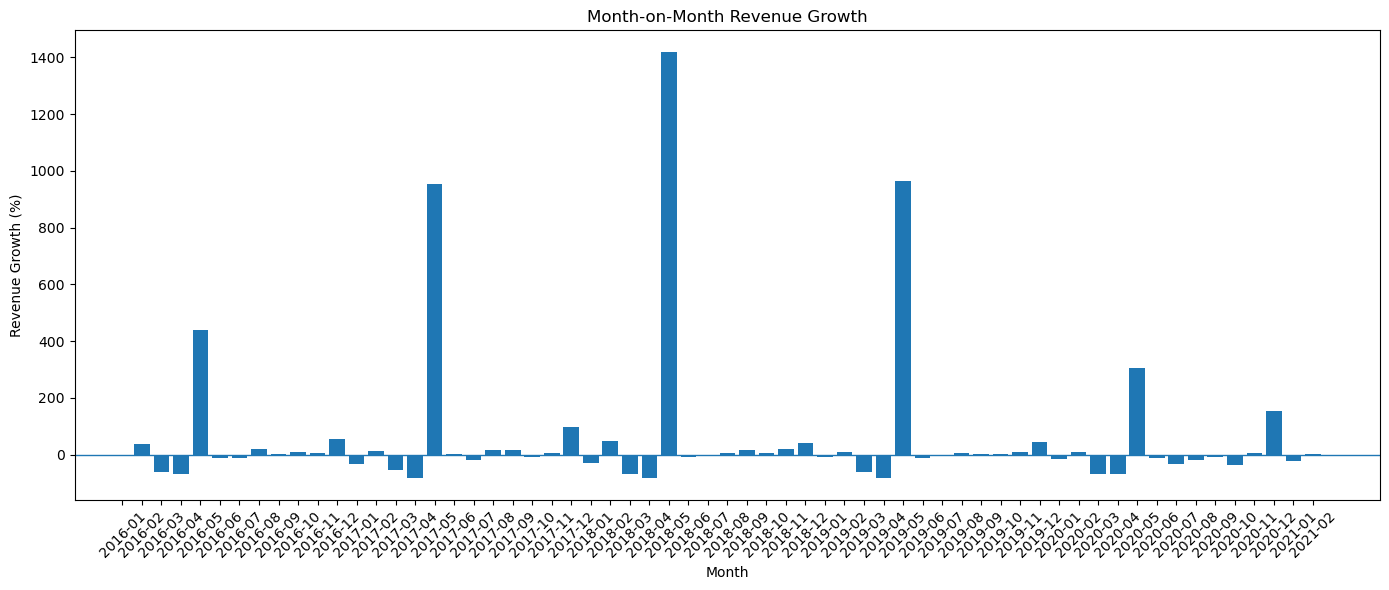

,year_month,revenue_usd,revenue_change,mom_growth_pct
0,2016-01,"649,918.78",NaN,NaN
1,2016-02,"891,098.30","241,179.52",37.11
2,2016-03,"338,407.36","-552,690.94",-62.02
3,2016-04,"110,591.63","-227,815.73",-67.32
4,2016-05,"595,986.18","485,394.55",438.91
5,2016-06,"518,585.28","-77,400.90",-12.99
6,2016-07,"454,959.83","-63,625.45",-12.27
7,2016-08,"547,512.69","92,552.86",20.34
8,2016-09,"567,421.12","19,908.43",3.64
9,2016-10,"623,959.57","56,538.45",9.96


In [54]:
# Analyse month-on-month revenue growth

plt.figure(figsize=(14, 6))

plt.bar(
    monthly_performance["year_month"],
    monthly_performance["mom_growth_pct"]
)

plt.axhline(0, linewidth=1)

plt.title("Month-on-Month Revenue Growth")
plt.xlabel("Month")
plt.ylabel("Revenue Growth (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

display(
    monthly_performance[
        [
            "year_month",
            "revenue_usd",
            "revenue_change",
            "mom_growth_pct"
        ]
    ]
)

## 7. Revenue and Profitability Trends

This section examines the relationship between revenue generation and gross profitability over time.

The analysis evaluates whether increases in sales revenue are accompanied by improvements in gross profit.

It examines:

- Monthly revenue trends.
- Monthly gross profit trends.
- Monthly gross profit margins.
- Revenue and gross profit relationships.

This helps management distinguish between sales growth and profitable growth.

Increasing revenue does not necessarily indicate improving profitability if product costs increase at a faster rate.

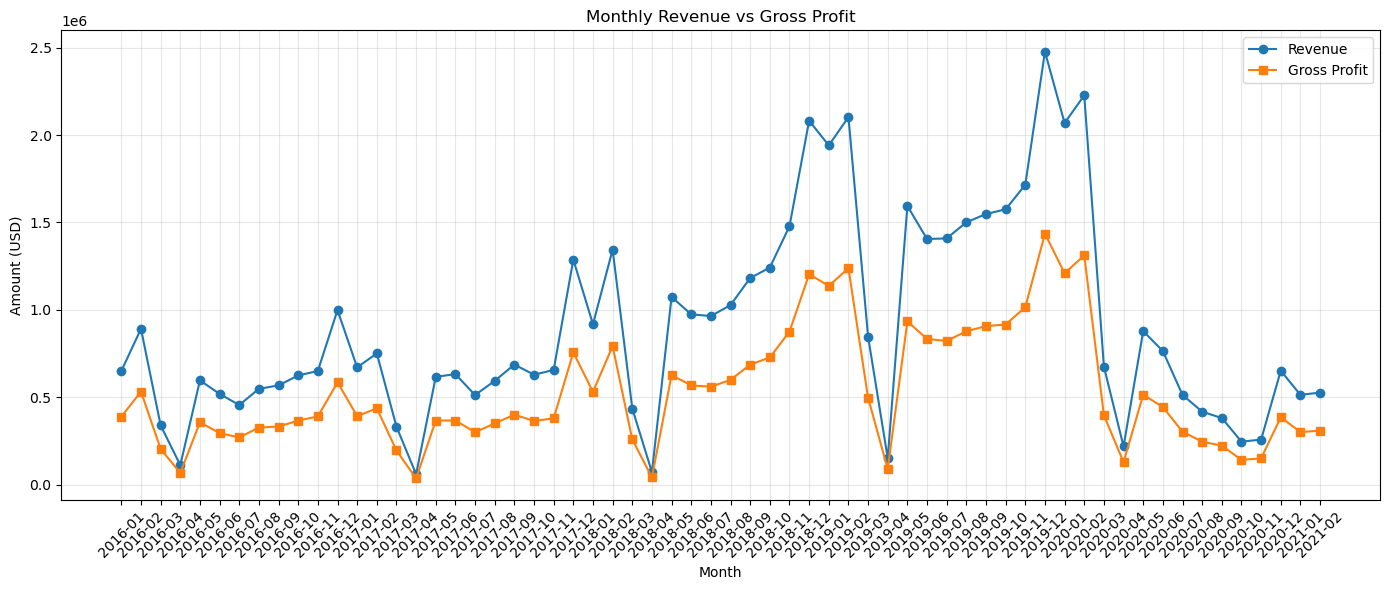

In [55]:
# Plot revenue and gross profit trends

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance["year_month"],
    monthly_performance["revenue_usd"],
    marker="o",
    label="Revenue"
)

plt.plot(
    monthly_performance["year_month"],
    monthly_performance["gross_profit_usd"],
    marker="s",
    label="Gross Profit"
)

plt.title("Monthly Revenue vs Gross Profit")
plt.xlabel("Month")
plt.ylabel("Amount (USD)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

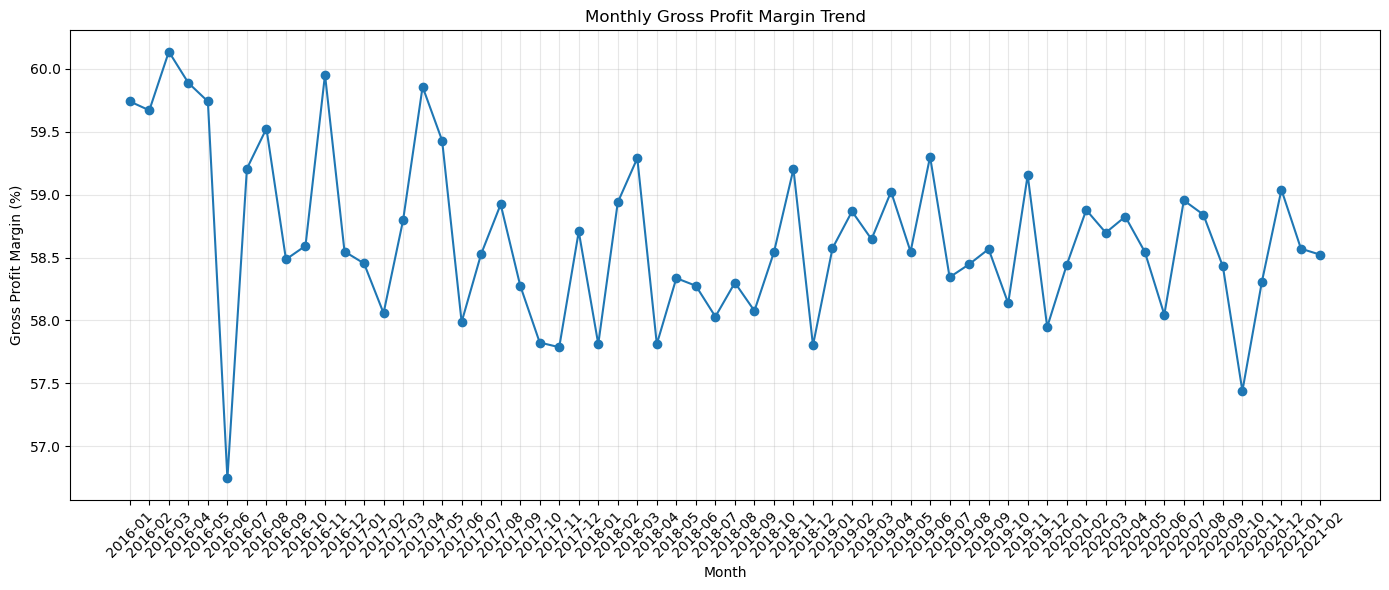

,year_month,revenue_usd,gross_profit_usd,gross_profit_margin
0,2016-01,"649,918.78","388,268.96",59.74
1,2016-02,"891,098.30","531,722.75",59.67
2,2016-03,"338,407.36","203,506.99",60.14
3,2016-04,"110,591.63","66,231.19",59.89
4,2016-05,"595,986.18","356,049.32",59.74
5,2016-06,"518,585.28","294,270.49",56.74
6,2016-07,"454,959.83","269,369.43",59.21
7,2016-08,"547,512.69","325,909.91",59.53
8,2016-09,"567,421.12","331,859.55",58.49
9,2016-10,"623,959.57","365,597.98",58.59


In [56]:
# Analyse monthly gross profit margins

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance["year_month"],
    monthly_performance["gross_profit_margin"],
    marker="o"
)

plt.title("Monthly Gross Profit Margin Trend")
plt.xlabel("Month")
plt.ylabel("Gross Profit Margin (%)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(
    monthly_performance[
        [
            "year_month",
            "revenue_usd",
            "gross_profit_usd",
            "gross_profit_margin"
        ]
    ]
)

## 8. Product Category Contribution Analysis

This section measures the contribution of individual product categories to overall retail performance.

The analysis examines:

- Revenue contribution by category.
- Gross profit contribution by category.
- Percentage of total revenue.
- Percentage of total gross profit.
- Gross profit margins by category.

Contribution analysis helps management identify the categories responsible for the largest proportion of commercial value.

It also highlights categories that generate substantial revenue but contribute relatively little to gross profit.

In [57]:
# Calculate category contribution

category_commercial = (
    sales.groupby("category", dropna=False)
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        product_cost_usd=("product_cost_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        units_sold=("quantity", "sum"),
        orders=("order_number", "nunique")
    )
    .reset_index()
)

category_commercial["revenue_contribution_pct"] = (
    category_commercial["revenue_usd"] /
    total_revenue * 100
)

category_commercial["profit_contribution_pct"] = (
    category_commercial["gross_profit_usd"] /
    total_gross_profit * 100
)

category_commercial["gross_profit_margin"] = np.where(
    category_commercial["revenue_usd"] != 0,
    category_commercial["gross_profit_usd"] /
    category_commercial["revenue_usd"] * 100,
    np.nan
)

category_commercial = category_commercial.sort_values(
    "revenue_usd",
    ascending=False
)

display(category_commercial)

,category,revenue_usd,product_cost_usd,gross_profit_usd,units_sold,orders,revenue_contribution_pct,profit_contribution_pct,gross_profit_margin
3,Computers,"19,301,595.46","8,024,147.56","11,277,447.90",44151,10990,34.62,34.53,58.43
5,Home Appliances,"10,795,478.59","4,499,139.74","6,296,338.85",18401,5195,19.36,19.28,58.32
1,Cameras and camcorders,"6,520,168.02","2,600,367.03","3,919,800.99",17609,4995,11.69,12.00,60.12
2,Cell phones,"6,183,791.22","2,685,164.68","3,498,626.54",31477,8442,11.09,10.71,56.58
7,TV and Video,"5,928,982.69","2,392,288.30","3,536,694.39",11236,3325,10.63,10.83,59.65
0,Audio,"3,169,627.74","1,341,775.97","1,827,851.77",23490,6625,5.68,5.60,57.67
6,"Music, Movies and Audio Books","3,131,006.44","1,221,747.27","1,909,259.17",28802,7784,5.62,5.85,60.98
4,Games and Toys,"724,829.43","328,160.66","396,668.77",22591,6128,1.30,1.21,54.73


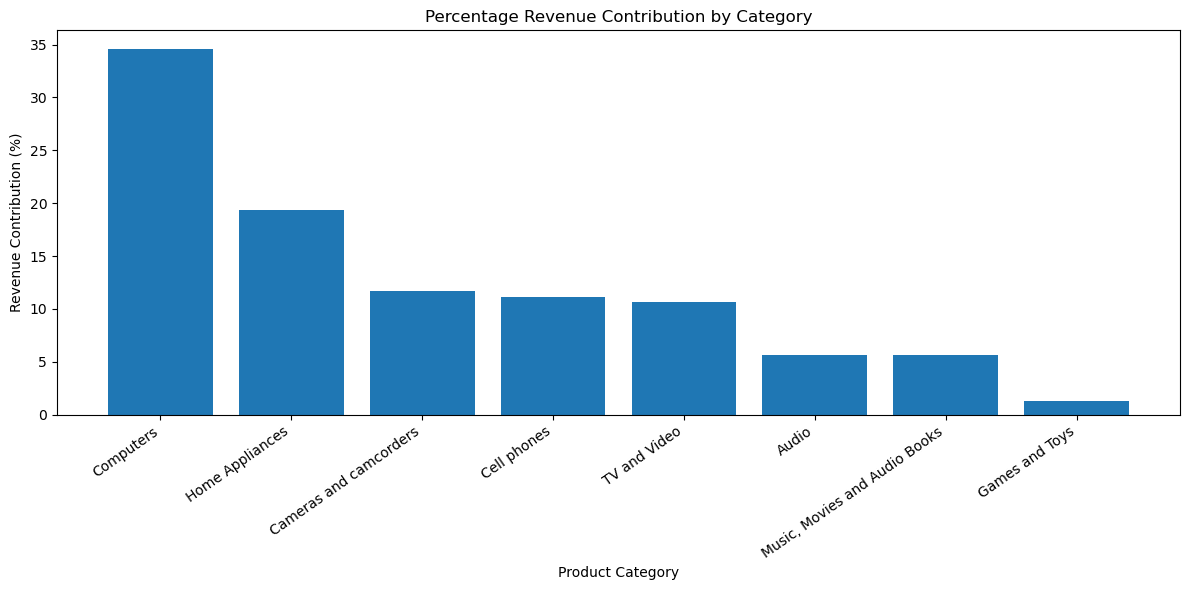

In [58]:
# Visualise category revenue contribution

plt.figure(figsize=(12, 6))

plt.bar(
    category_commercial["category"].astype(str),
    category_commercial["revenue_contribution_pct"]
)

plt.title("Percentage Revenue Contribution by Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue Contribution (%)")

plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

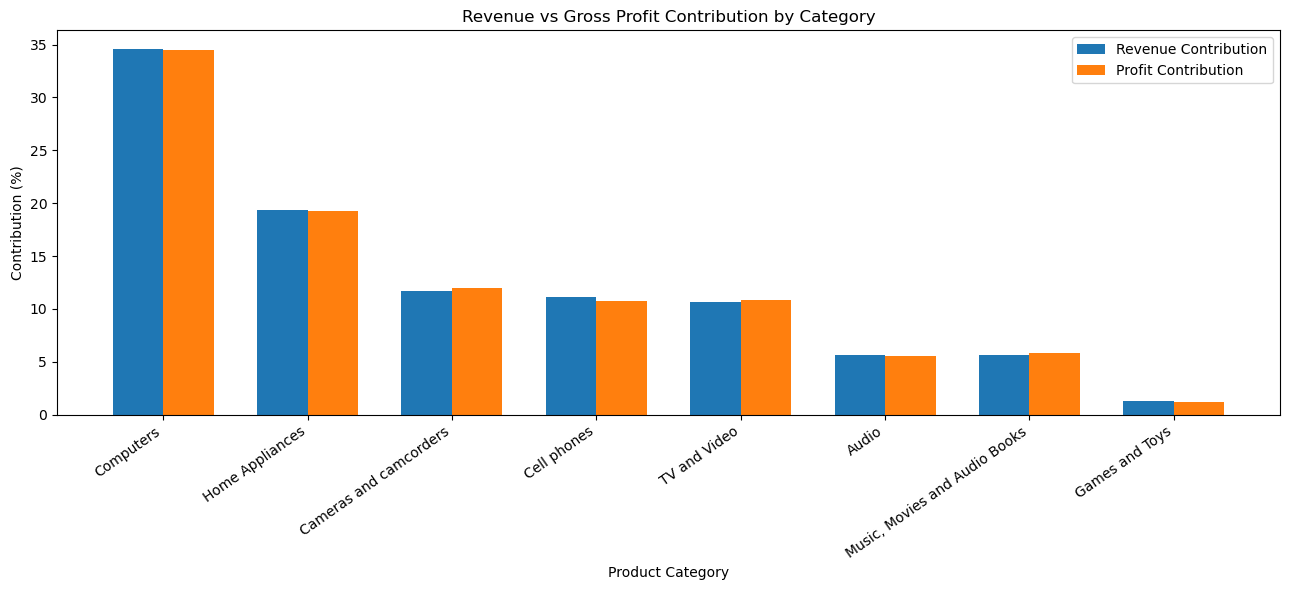

In [59]:
# Compare revenue and profit contribution

x = np.arange(len(category_commercial))
width = 0.35

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    category_commercial["revenue_contribution_pct"],
    width,
    label="Revenue Contribution"
)

plt.bar(
    x + width / 2,
    category_commercial["profit_contribution_pct"],
    width,
    label="Profit Contribution"
)

plt.title("Revenue vs Gross Profit Contribution by Category")
plt.xlabel("Product Category")
plt.ylabel("Contribution (%)")

plt.xticks(
    x,
    category_commercial["category"].astype(str),
    rotation=35,
    ha="right"
)

plt.legend()
plt.tight_layout()
plt.show()

## 9. Product Performance and Ranking

This section evaluates individual product performance using commercial indicators.

Products are ranked according to:

- Total revenue.
- Gross profit.
- Units sold.
- Gross profit margin.

The analysis distinguishes between products that generate high sales volumes and those that generate substantial financial returns.

A product may sell frequently without necessarily being one of the most profitable products.

These rankings can support product portfolio decisions, promotional planning and inventory prioritisation.

In [60]:
# Identify product grouping fields

product_group_columns = ["product_key"]

for col in ["product_name", "brand", "category"]:
    if col in sales.columns:
        product_group_columns.append(col)


# Aggregate product commercial performance

product_commercial = (
    sales.groupby(product_group_columns, dropna=False)
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        product_cost_usd=("product_cost_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        units_sold=("quantity", "sum"),
        orders=("order_number", "nunique")
    )
    .reset_index()
)

product_commercial["gross_profit_margin"] = np.where(
    product_commercial["revenue_usd"] != 0,
    product_commercial["gross_profit_usd"] /
    product_commercial["revenue_usd"] * 100,
    np.nan
)

product_commercial["revenue_rank"] = (
    product_commercial["revenue_usd"]
    .rank(method="dense", ascending=False)
)

product_commercial["profit_rank"] = (
    product_commercial["gross_profit_usd"]
    .rank(method="dense", ascending=False)
)

product_commercial["units_rank"] = (
    product_commercial["units_sold"]
    .rank(method="dense", ascending=False)
)

display(
    product_commercial.sort_values("revenue_rank").head(15)
)

,product_key,product_name,brand,category,revenue_usd,product_cost_usd,gross_profit_usd,units_sold,orders,gross_profit_margin,revenue_rank,profit_rank,units_rank
442,444,WWI Desktop PC2.33 X2330 Black,Wide World Importers,Computers,"505,450.00","167,464.00","337,986.00",550,154,66.87,1.00,1.00,1.00
414,416,Adventure Works Desktop PC2.33 XD233 Silver,Adventure Works,Computers,"466,089.00","154,425.05","311,663.95",481,146,66.87,2.00,2.00,11.00
426,428,Adventure Works Desktop PC2.33 XD233 Brown,Adventure Works,Computers,"464,151.00","153,782.95","310,368.05",479,144,66.87,3.00,3.00,13.00
420,422,Adventure Works Desktop PC2.33 XD233 Black,Adventure Works,Computers,"447,678.00","148,325.10","299,352.90",462,151,66.87,4.00,4.00,17.00
431,433,Adventure Works Desktop PC2.33 XD233 White,Adventure Works,Computers,"437,019.00","144,793.55","292,225.45",451,141,66.87,5.00,5.00,23.00
453,455,WWI Desktop PC2.33 X2330 White,Wide World Importers,Computers,"424,578.00","140,669.76","283,908.24",462,131,66.87,6.00,6.00,17.00
448,450,WWI Desktop PC2.33 X2330 Brown,Wide World Importers,Computers,"422,740.00","140,060.80","282,679.20",460,151,66.87,7.00,7.00,18.00
146,147,"Adventure Works 52"" LCD HDTV X590 White",Adventure Works,TV and Video,"394,398.64","130,671.52","263,727.12",136,40,66.87,8.00,8.00,219.00
145,146,"Adventure Works 52"" LCD HDTV X590 Black",Adventure Works,TV and Video,"374,098.71","123,945.78","250,152.93",129,44,66.87,9.00,9.00,225.00
436,438,WWI Desktop PC2.33 X2330 Silver,Wide World Importers,Computers,"360,248.00","119,356.16","240,891.84",392,141,66.87,10.00,10.00,37.00


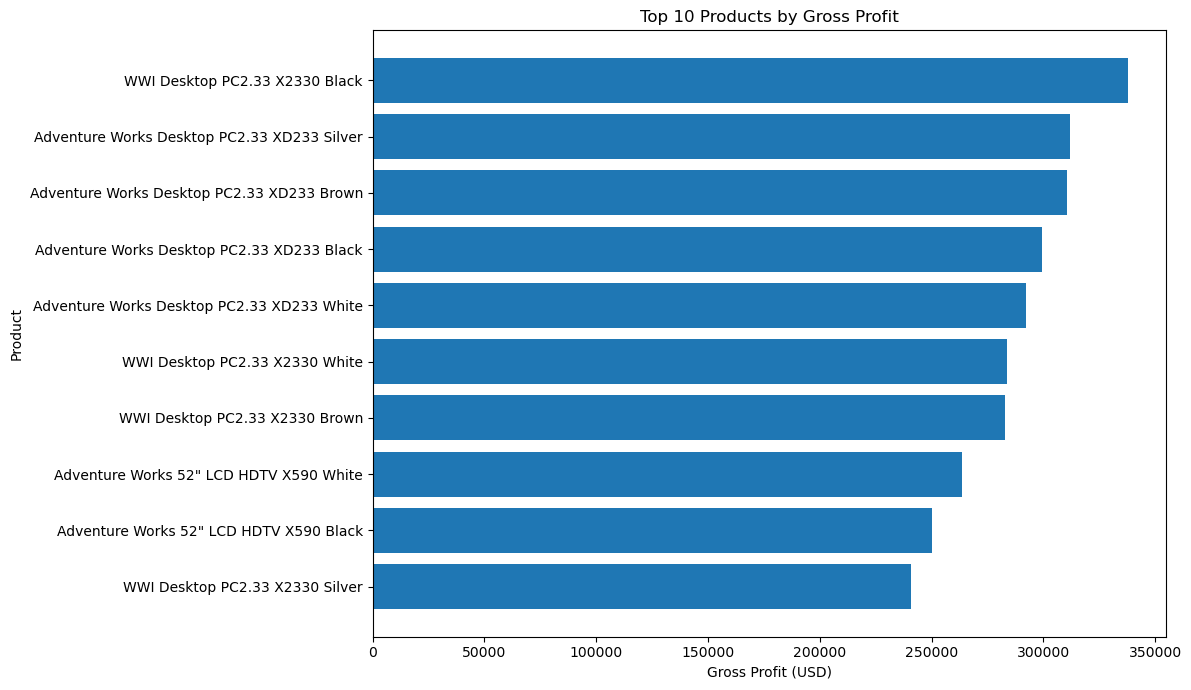

In [61]:
# Top 10 products by gross profit

top_profit_products = (
    product_commercial
    .sort_values("gross_profit_usd", ascending=False)
    .head(10)
)

product_labels = (
    top_profit_products["product_name"].astype(str)
    if "product_name" in top_profit_products.columns
    else top_profit_products["product_key"].astype(str)
)

plt.figure(figsize=(12, 7))

plt.barh(
    product_labels,
    top_profit_products["gross_profit_usd"]
)

plt.title("Top 10 Products by Gross Profit")
plt.xlabel("Gross Profit (USD)")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [62]:
# Identify high-volume and high-profit products

top_volume_products = (
    product_commercial
    .sort_values("units_sold", ascending=False)
    .head(10)
)

display(
    top_volume_products[
        product_group_columns + [
            "units_sold",
            "revenue_usd",
            "gross_profit_usd",
            "gross_profit_margin"
        ]
    ]
)

,product_key,product_name,brand,category,units_sold,revenue_usd,gross_profit_usd,gross_profit_margin
442,444,WWI Desktop PC2.33 X2330 Black,Wide World Importers,Computers,550,"505,450.00","337,986.00",66.87
456,458,WWI Desktop PC1.80 E1800 White,Wide World Importers,Computers,538,"123,686.20","60,627.22",49.02
432,434,Adventure Works Desktop PC2.30 MD230 White,Adventure Works,Computers,521,"312,079.00","168,564.34",54.01
422,424,Adventure Works Desktop PC1.60 ED160 Black,Adventure Works,Computers,521,"140,643.95","68,938.72",49.02
423,425,Adventure Works Desktop PC1.80 ED180 Black,Adventure Works,Computers,520,"191,880.00","94,052.40",49.02
421,423,Adventure Works Desktop PC2.30 MD230 Black,Adventure Works,Computers,514,"307,886.00","166,299.56",54.01
444,446,WWI Desktop PC1.60 E1600 Black,Wide World Importers,Computers,509,"111,954.55","54,875.29",49.02
438,440,WWI Desktop PC1.60 E1600 Silver,Wide World Importers,Computers,507,"111,514.65","54,659.67",49.02
433,435,Adventure Works Desktop PC1.60 ED160 White,Adventure Works,Computers,505,"136,324.75","66,821.60",49.02
450,452,WWI Desktop PC1.60 E1600 Red,Wide World Importers,Computers,505,"111,074.75","54,444.05",49.02


## 10. Store Commercial Performance

This section compares the commercial performance of individual retail stores.

The analysis examines:

- Revenue by store.
- Gross profit by store.
- Gross profit margin by store.
- Number of orders.
- Units sold.
- Average order value.

Store-level comparisons help management identify high-performing locations and stores that may require additional investigation.

Differences in performance should be interpreted alongside store size, operating periods and market characteristics where available.

In [63]:
# Identify available store descriptive fields

store_descriptive_columns = [
    col for col in [
        "store_name",
        "store_city",
        "store_state",
        "store_country"
    ]
    if col in sales.columns
]

store_group_columns = ["store_key"] + [
    col for col in store_descriptive_columns
    if col not in ["store_state", "store_country"]
]

# Aggregate store performance

store_commercial = (
    sales.groupby(store_group_columns, dropna=False)
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        product_cost_usd=("product_cost_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        orders=("order_number", "nunique"),
        units_sold=("quantity", "sum"),
        customers=("customer_key", "nunique")
    )
    .reset_index()
)

store_commercial["gross_profit_margin"] = np.where(
    store_commercial["revenue_usd"] != 0,
    store_commercial["gross_profit_usd"] /
    store_commercial["revenue_usd"] * 100,
    np.nan
)

store_commercial["average_order_value"] = np.where(
    store_commercial["orders"] != 0,
    store_commercial["revenue_usd"] /
    store_commercial["orders"],
    np.nan
)

store_commercial = store_commercial.sort_values(
    "revenue_usd",
    ascending=False
)

display(store_commercial.head(20))

,store_key,revenue_usd,product_cost_usd,gross_profit_usd,orders,units_sold,customers,gross_profit_margin,average_order_value
0,0,"11,404,324.63","4,731,631.99","6,672,692.64",5580,41311,4547,58.51,"2,043.79"
48,55,"1,417,885.41","587,333.66","830,551.75",622,4826,533,58.58,"2,279.56"
44,50,"1,394,738.06","575,078.94","819,659.12",605,4773,508,58.77,"2,305.35"
47,54,"1,384,396.24","574,096.18","810,300.06",629,4686,559,58.53,"2,200.95"
7,9,"1,336,150.06","561,392.51","774,757.55",658,4894,515,57.98,"2,030.62"
50,57,"1,325,611.89","541,516.13","784,095.76",605,4407,540,59.15,"2,191.09"
40,45,"1,318,787.92","557,516.10","761,271.82",617,4672,523,57.73,"2,137.42"
52,61,"1,305,684.43","540,687.23","764,997.20",624,4771,525,58.59,"2,092.44"
51,59,"1,302,272.44","547,570.12","754,702.32",619,4674,515,57.95,"2,103.83"
55,64,"1,259,350.98","514,066.99","745,283.99",566,4289,502,59.18,"2,225.00"


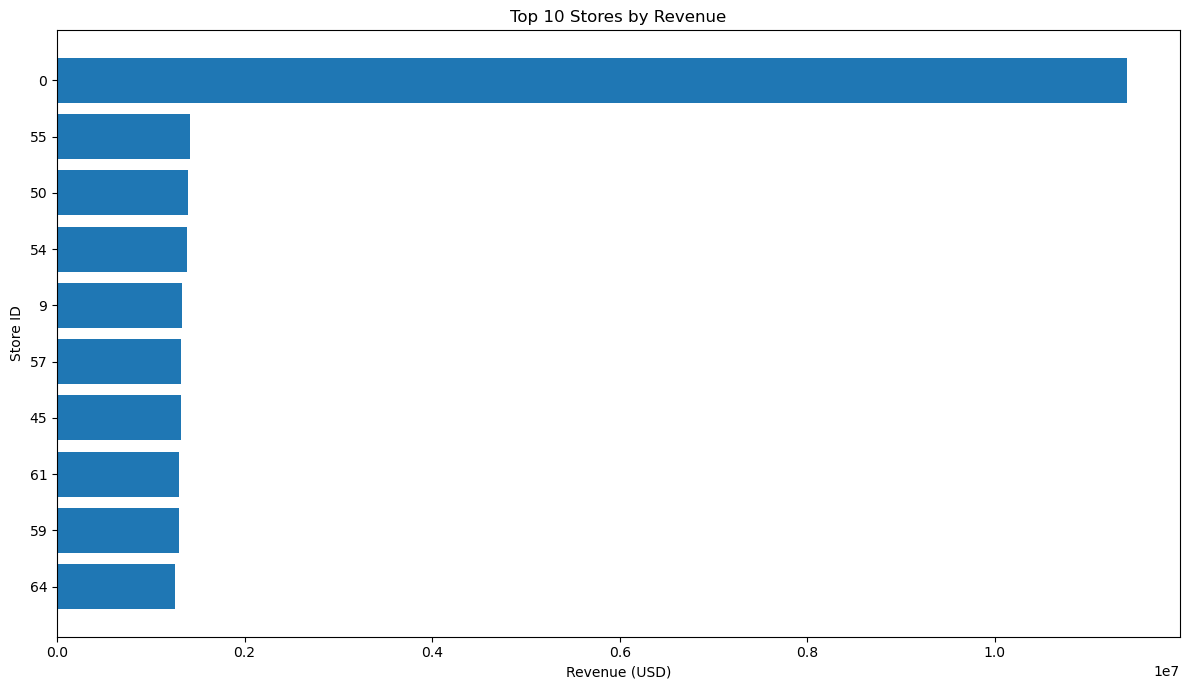

In [64]:
# Compare top 10 stores by revenue

top_stores = store_commercial.head(10).copy()

plt.figure(figsize=(12, 7))

plt.barh(
    top_stores["store_key"].astype(str),
    top_stores["revenue_usd"]
)

plt.title("Top 10 Stores by Revenue")
plt.xlabel("Revenue (USD)")
plt.ylabel("Store ID")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

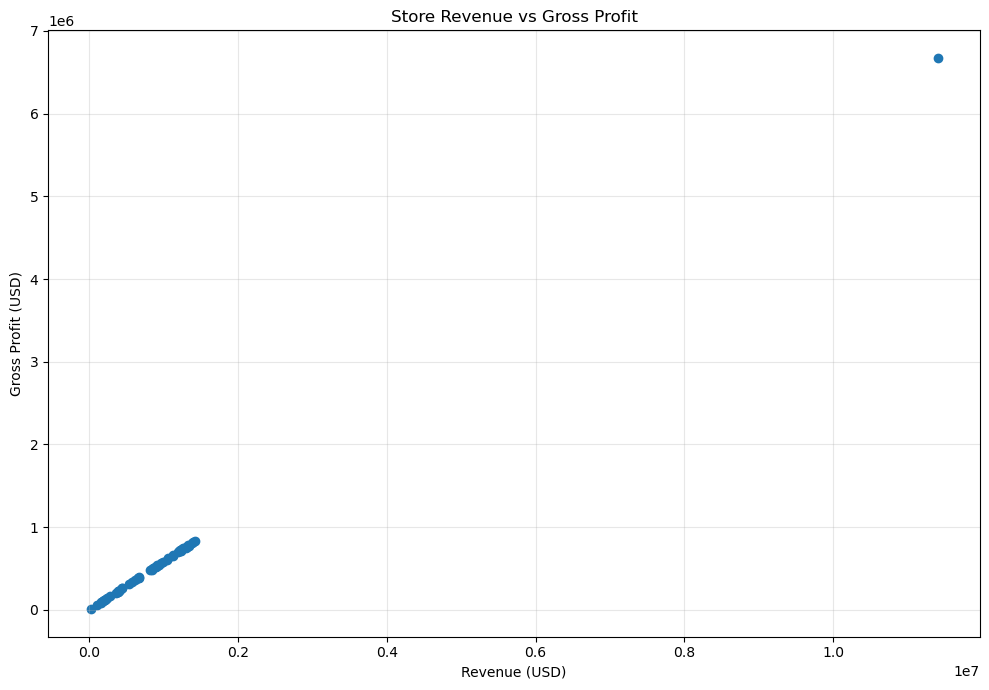

In [65]:
# Compare store revenue and profitability

plt.figure(figsize=(10, 7))

plt.scatter(
    store_commercial["revenue_usd"],
    store_commercial["gross_profit_usd"]
)

plt.title("Store Revenue vs Gross Profit")
plt.xlabel("Revenue (USD)")
plt.ylabel("Gross Profit (USD)")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Customer Value and Purchasing Behaviour

This section evaluates the commercial value generated by individual customers.

The analysis examines:

- Customer revenue contribution.
- Customer gross profit contribution.
- Number of purchases.
- Total units purchased.
- Average order value by customer.
- Customer purchasing frequency.

The objective is to understand how customer purchasing activity contributes to overall retail performance.

Customers with high revenue contributions may represent important commercial relationships, while customers with relatively low purchasing activity may present opportunities for engagement.

In [66]:
# Aggregate customer commercial performance

customer_commercial = (
    sales.groupby("customer_key")
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        total_units=("quantity", "sum"),
        total_orders=("order_number", "nunique"),
        first_purchase=("order_date", "min"),
        last_purchase=("order_date", "max")
    )
    .reset_index()
)

customer_commercial["average_order_value"] = np.where(
    customer_commercial["total_orders"] > 0,
    customer_commercial["revenue_usd"] /
    customer_commercial["total_orders"],
    np.nan
)

customer_commercial = customer_commercial.sort_values(
    "revenue_usd",
    ascending=False
)

display(customer_commercial.head(15))

,customer_key,revenue_usd,gross_profit_usd,total_units,total_orders,first_purchase,last_purchase,average_order_value
9371,1702221,"61,871.70","39,606.02",75,9,2016-05-02,2019-12-27,"6,874.63"
10515,1884663,"43,517.80","28,819.96",30,3,2018-11-12,2019-02-20,"14,505.93"
11072,1969704,"42,788.04","26,008.23",60,7,2016-08-13,2020-01-02,"6,112.58"
2743,535496,"41,521.53","26,957.37",35,3,2016-12-24,2018-11-24,"13,840.51"
2840,551036,"40,556.54","26,716.09",36,4,2017-12-12,2020-12-25,"10,139.14"
3664,723572,"40,225.01","23,440.78",124,14,2016-02-20,2021-02-20,"2,873.22"
1175,262871,"38,813.88","23,986.19",32,3,2017-12-25,2020-02-20,"12,937.96"
10795,1928466,"38,191.06","24,054.60",40,4,2016-08-15,2019-11-21,"9,547.76"
8116,1503831,"37,319.88","22,881.47",29,3,2018-07-18,2018-12-26,"12,439.96"
7275,1373561,"36,817.28","22,954.48",62,5,2017-01-26,2019-11-23,"7,363.46"


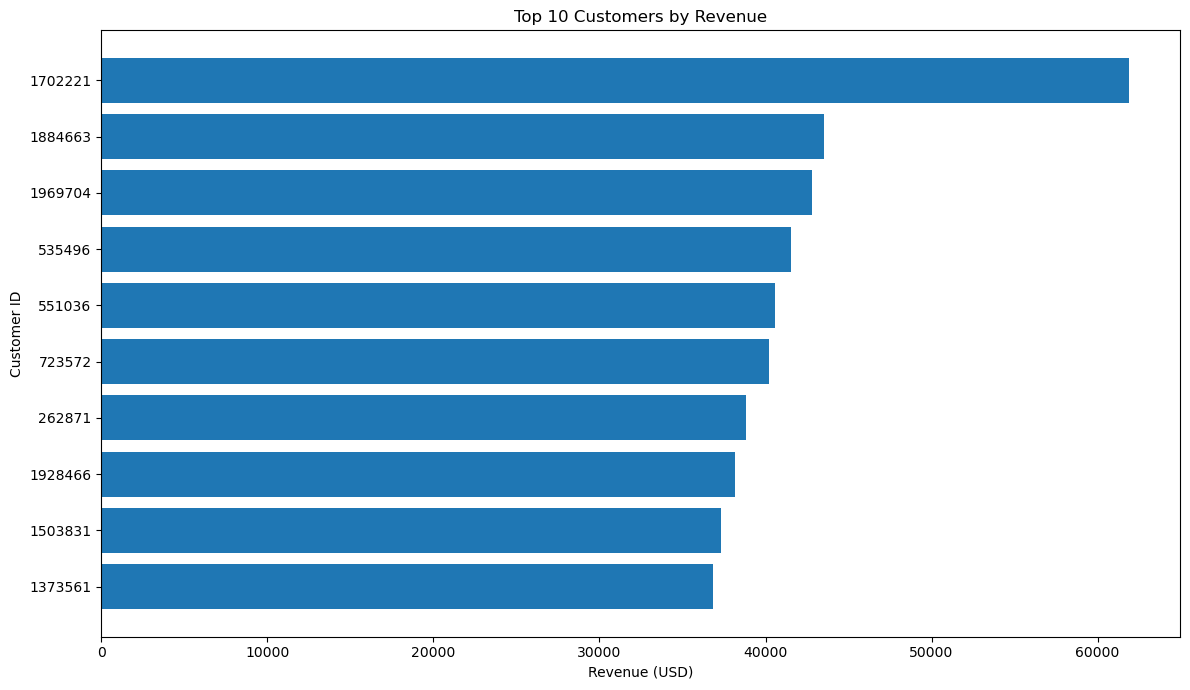

In [67]:
# Identify the top 10 customers by revenue

top_customers = (
    customer_commercial
    .sort_values("revenue_usd", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_customers["customer_key"].astype(str),
    top_customers["revenue_usd"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (USD)")
plt.ylabel("Customer ID")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [68]:
# Calculate customer revenue concentration

customer_commercial["revenue_contribution_pct"] = (
    customer_commercial["revenue_usd"] /
    total_revenue * 100
)

customer_commercial = customer_commercial.sort_values(
    "revenue_usd",
    ascending=False
)

customer_commercial["cumulative_revenue_pct"] = (
    customer_commercial["revenue_contribution_pct"].cumsum()
)

display(
    customer_commercial[
        [
            "customer_key",
            "revenue_usd",
            "revenue_contribution_pct",
            "cumulative_revenue_pct"
        ]
    ].head(20)
)

,customer_key,revenue_usd,revenue_contribution_pct,cumulative_revenue_pct
9371,1702221,"61,871.70",0.11,0.11
10515,1884663,"43,517.80",0.08,0.19
11072,1969704,"42,788.04",0.08,0.27
2743,535496,"41,521.53",0.07,0.34
2840,551036,"40,556.54",0.07,0.41
3664,723572,"40,225.01",0.07,0.49
1175,262871,"38,813.88",0.07,0.55
10795,1928466,"38,191.06",0.07,0.62
8116,1503831,"37,319.88",0.07,0.69
7275,1373561,"36,817.28",0.07,0.76


## 12. Customer Segmentation Using RFM Analysis

RFM analysis is a customer segmentation technique that evaluates purchasing behaviour using three dimensions:

### Recency
Measures how recently a customer made a purchase.

Customers who purchased more recently generally receive higher recency scores.

### Frequency
Measures how often a customer purchases.

Customers with more purchases receive higher frequency scores.

### Monetary Value
Measures the total revenue generated by a customer.

Customers generating greater revenue receive higher monetary scores.

### RFM Segmentation

Customers will be assigned scores from 1 to 5 for each dimension using quintile-based ranking.

The resulting scores will be used to identify customer groups such as:

- Champions.
- Loyal Customers.
- Potential Loyalists.
- At-Risk Customers.
- Others.

The segmentation provides a framework for developing targeted customer engagement and retention strategies.

RFM is a behavioural segmentation method and should not be interpreted as a predictive model of future customer behaviour.

In [69]:
# Prepare customer-level RFM data

reference_date = sales["order_date"].max() + pd.Timedelta(days=1)

rfm = (
    sales.dropna(subset=["order_date"])
    .groupby("customer_key")
    .agg(
        recency=("order_date", lambda x: (
            reference_date - x.max()
        ).days),
        frequency=("order_number", "nunique"),
        monetary=("revenue_usd", "sum")
    )
    .reset_index()
)

print("RFM reference date:", reference_date.date())

display(rfm.head(10))

RFM reference date: 2021-02-21


,customer_key,recency,frequency,monetary
0,301,468,1,592.00
1,325,414,3,"5,787.67"
2,554,444,2,951.71
3,1042,1083,1,"1,124.91"
4,1314,1160,1,"2,539.86"
5,1568,11,4,"4,922.43"
6,1585,724,2,"6,700.62"
7,1626,365,2,"2,940.35"
8,1642,642,1,115.98
9,1863,197,2,"2,198.25"


In [70]:
# Generate RFM scores using percentile ranking

# Recency: lower days since purchase is better
rfm["R_score"] = (
    pd.qcut(
        rfm["recency"].rank(method="first"),
        5,
        labels=[5, 4, 3, 2, 1]
    ).astype(int)
)

# Frequency: more purchases is better
rfm["F_score"] = (
    pd.qcut(
        rfm["frequency"].rank(method="first"),
        5,
        labels=[1, 2, 3, 4, 5]
    ).astype(int)
)

# Monetary: greater revenue is better
rfm["M_score"] = (
    pd.qcut(
        rfm["monetary"].rank(method="first"),
        5,
        labels=[1, 2, 3, 4, 5]
    ).astype(int)
)

# Combine RFM scores
rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

rfm["RFM_total"] = (
    rfm["R_score"] +
    rfm["F_score"] +
    rfm["M_score"]
)

display(rfm.head(15))

,customer_key,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total
0,301,468,1,592.00,3,1,1,311,5
1,325,414,3,"5,787.67",4,4,4,444,12
2,554,444,2,951.71,3,2,2,322,7
3,1042,1083,1,"1,124.91",1,1,2,112,4
4,1314,1160,1,"2,539.86",1,1,3,113,5
5,1568,11,4,"4,922.43",5,5,4,554,14
6,1585,724,2,"6,700.62",2,2,4,224,8
7,1626,365,2,"2,940.35",4,2,3,423,9
8,1642,642,1,115.98,2,1,1,211,4
9,1863,197,2,"2,198.25",5,2,3,523,10


In [71]:
# Assign customer segments

def assign_segment(row):

    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif r >= 4 and f <= 2:
        return "Potential Loyalists"

    elif r <= 2 and f >= 3:
        return "At-Risk Customers"

    elif r <= 2 and f <= 2:
        return "Hibernating Customers"

    else:
        return "Others"


rfm["customer_segment"] = rfm.apply(
    assign_segment,
    axis=1
)

display(
    rfm.sort_values(
        "RFM_total",
        ascending=False
    ).head(20)
)

,customer_key,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total,customer_segment
3917,770560,290,5,"14,098.25",5,5,5,555,15,Champions
7398,1389867,58,6,"12,032.71",5,5,5,555,15,Champions
3385,660940,247,4,"10,898.98",5,5,5,555,15,Champions
9750,1760076,129,6,"27,502.48",5,5,5,555,15,Champions
7418,1393169,270,4,"10,483.52",5,5,5,555,15,Champions
3383,660527,197,7,"21,470.27",5,5,5,555,15,Champions
11338,2011298,55,5,"13,106.64",5,5,5,555,15,Champions
7410,1392092,155,4,"10,181.54",5,5,5,555,15,Champions
1586,336348,58,4,"24,379.10",5,5,5,555,15,Champions
2646,519586,247,4,"19,564.18",5,5,5,555,15,Champions


In [72]:
# Summarise customer segments

segment_performance = (
    rfm.groupby("customer_segment")
    .agg(
        customers=("customer_key", "count"),
        average_recency=("recency", "mean"),
        average_frequency=("frequency", "mean"),
        total_revenue=("monetary", "sum"),
        average_revenue=("monetary", "mean")
    )
    .reset_index()
)

segment_performance["customer_share_pct"] = (
    segment_performance["customers"] /
    segment_performance["customers"].sum() * 100
)

segment_performance["revenue_contribution_pct"] = (
    segment_performance["total_revenue"] /
    segment_performance["total_revenue"].sum() * 100
)

display(
    segment_performance.sort_values(
        "total_revenue",
        ascending=False
    )
)

,customer_segment,customers,average_recency,average_frequency,total_revenue,average_revenue,customer_share_pct,revenue_contribution_pct
1,Champions,1907,260.46,4.10,"19,742,710.38","10,352.76",16.04,35.41
0,At-Risk Customers,1850,856.28,2.49,"9,993,979.70","5,402.15",15.56,17.92
3,Loyal Customers,1892,400.79,3.19,"9,212,058.45","4,868.95",15.92,16.52
4,Others,2266,422.73,1.67,"7,867,849.04","3,472.13",19.06,14.11
2,Hibernating Customers,2905,"1,102.73",1.02,"6,734,012.33","2,318.08",24.44,12.08
5,Potential Loyalists,1067,292.17,1.04,"2,204,869.69","2,066.42",8.98,3.95


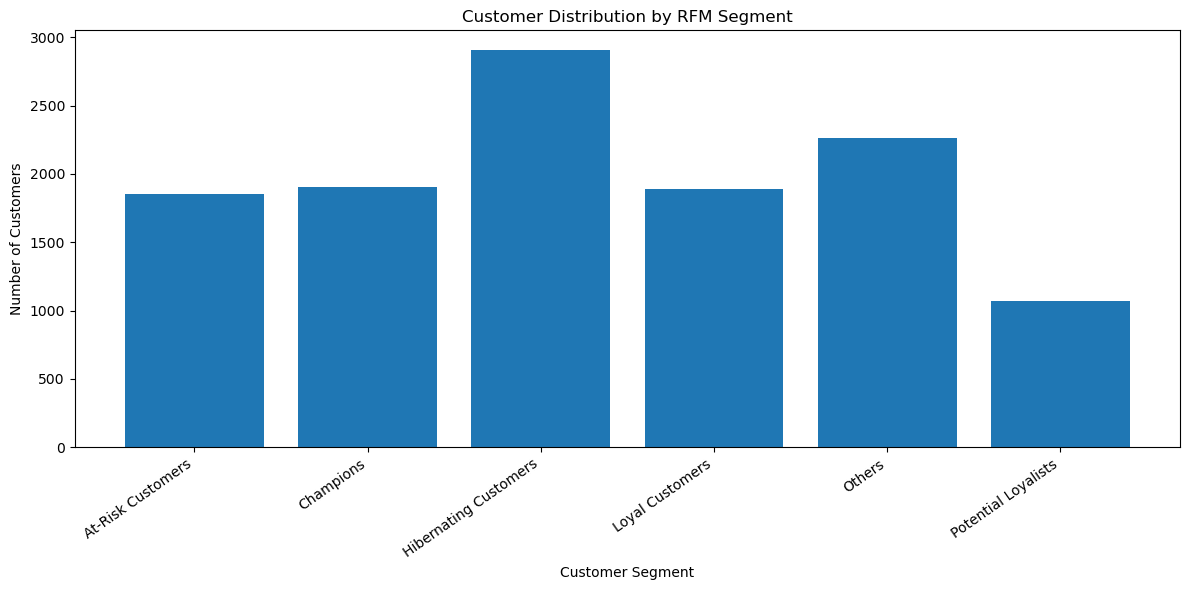

In [73]:
# Visualise customer segment distribution

plt.figure(figsize=(12, 6))

plt.bar(
    segment_performance["customer_segment"],
    segment_performance["customers"]
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

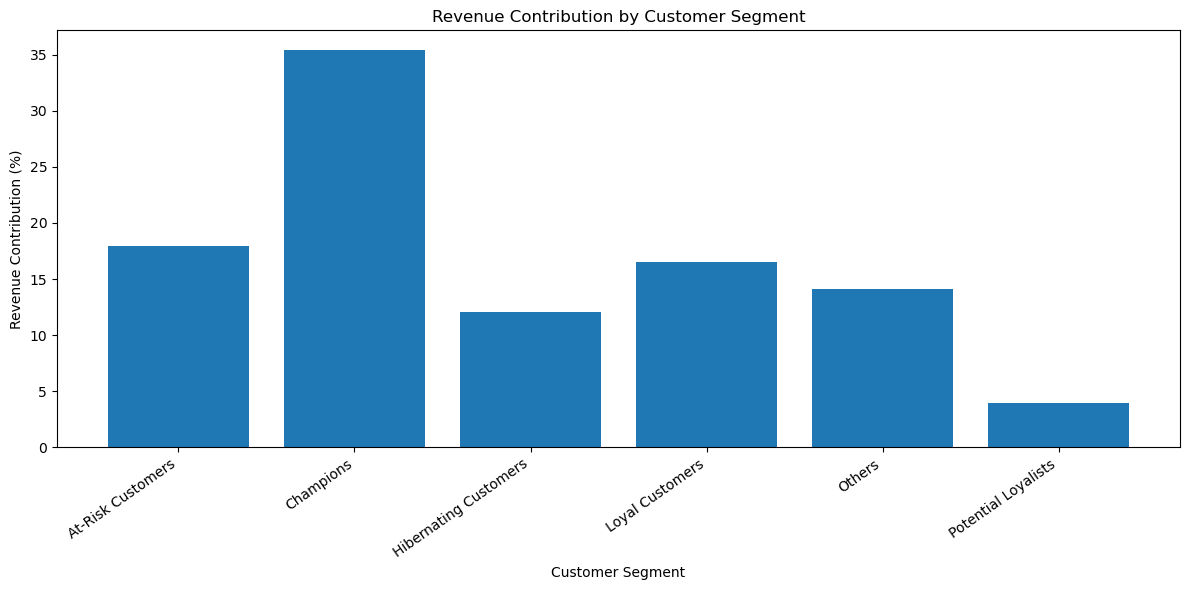

In [74]:
# Compare customer segment revenue contributions

plt.figure(figsize=(12, 6))

plt.bar(
    segment_performance["customer_segment"],
    segment_performance["revenue_contribution_pct"]
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Contribution (%)")

plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

## 13. Commercial Performance Benchmarking

This section compares commercial performance across product categories and retail stores.

Benchmarking uses the overall business performance as a reference point to identify segments performing above or below the business average.

The analysis evaluates:

- Category gross profit margins.
- Store gross profit margins.
- Revenue contribution.
- Gross profit contribution.
- Relative performance against overall gross profit margin.

The purpose is to identify commercial strengths and potential areas for further investigation.

The overall gross profit margin is used as a financial benchmark rather than an assumed industry standard.

In [75]:
# Benchmark category profitability

category_benchmark = category_commercial.copy()

category_benchmark["margin_difference_pp"] = (
    category_benchmark["gross_profit_margin"] -
    gross_profit_margin
)

category_benchmark["performance_status"] = np.where(
    category_benchmark["margin_difference_pp"] >= 0,
    "At or Above Business Average",
    "Below Business Average"
)

display(
    category_benchmark[
        [
            "category",
            "revenue_usd",
            "gross_profit_usd",
            "gross_profit_margin",
            "margin_difference_pp",
            "performance_status"
        ]
    ]
)

,category,revenue_usd,gross_profit_usd,gross_profit_margin,margin_difference_pp,performance_status
3,Computers,"19,301,595.46","11,277,447.90",58.43,-0.15,Below Business Average
5,Home Appliances,"10,795,478.59","6,296,338.85",58.32,-0.26,Below Business Average
1,Cameras and camcorders,"6,520,168.02","3,919,800.99",60.12,1.54,At or Above Business Average
2,Cell phones,"6,183,791.22","3,498,626.54",56.58,-2.00,Below Business Average
7,TV and Video,"5,928,982.69","3,536,694.39",59.65,1.07,At or Above Business Average
0,Audio,"3,169,627.74","1,827,851.77",57.67,-0.91,Below Business Average
6,"Music, Movies and Audio Books","3,131,006.44","1,909,259.17",60.98,2.40,At or Above Business Average
4,Games and Toys,"724,829.43","396,668.77",54.73,-3.86,Below Business Average


In [76]:
# Benchmark store profitability

store_benchmark = store_commercial.copy()

store_benchmark["margin_difference_pp"] = (
    store_benchmark["gross_profit_margin"] -
    gross_profit_margin
)

store_benchmark["performance_status"] = np.where(
    store_benchmark["margin_difference_pp"] >= 0,
    "At or Above Business Average",
    "Below Business Average"
)

display(
    store_benchmark.sort_values(
        "margin_difference_pp",
        ascending=False
    ).head(20)
)

,store_key,revenue_usd,product_cost_usd,gross_profit_usd,orders,units_sold,customers,gross_profit_margin,average_order_value,margin_difference_pp,performance_status
2,2,"15,175.99","5,663.38","9,512.61",4,61,4,62.68,"3,794.00",4.10,At or Above Business Average
13,16,"199,009.69","79,093.89","119,915.80",91,683,81,60.26,"2,186.92",1.67,At or Above Business Average
3,4,"442,475.02","176,103.37","266,371.65",174,1286,154,60.20,"2,542.96",1.62,At or Above Business Average
11,14,"105,714.05","42,122.50","63,591.55",57,361,55,60.15,"1,854.63",1.57,At or Above Business Average
30,34,"434,760.24","173,589.74","261,170.50",196,1465,173,60.07,"2,218.16",1.49,At or Above Business Average
15,18,"226,078.88","91,001.09","135,077.79",81,607,78,59.75,"2,791.10",1.17,At or Above Business Average
17,20,"388,594.07","157,064.95","231,529.12",183,1423,155,59.58,"2,123.46",1.00,At or Above Business Average
4,5,"859,678.19","349,720.70","509,957.49",371,2944,284,59.32,"2,317.19",0.74,At or Above Business Average
38,43,"1,250,255.14","509,162.14","741,093.00",558,4258,505,59.28,"2,240.60",0.69,At or Above Business Average
57,66,"1,220,964.38","497,774.17","723,190.21",545,3986,503,59.23,"2,240.30",0.65,At or Above Business Average


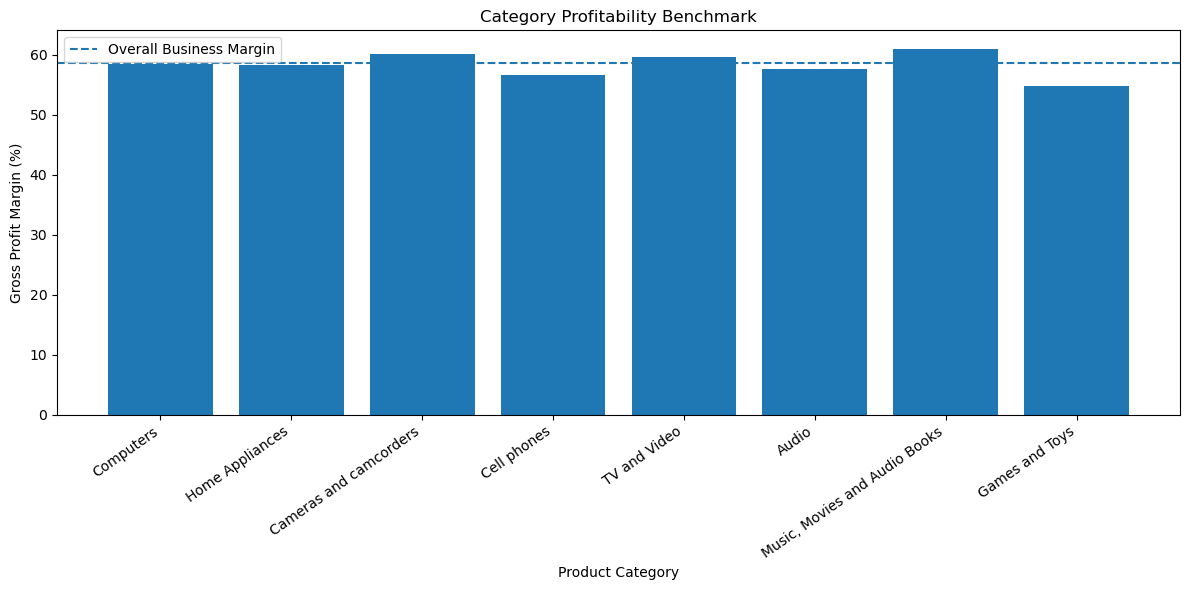

In [77]:
# Visualise category gross profit margin against business average

plt.figure(figsize=(12, 6))

plt.bar(
    category_benchmark["category"].astype(str),
    category_benchmark["gross_profit_margin"]
)

plt.axhline(
    gross_profit_margin,
    linestyle="--",
    label="Overall Business Margin"
)

plt.title("Category Profitability Benchmark")
plt.xlabel("Product Category")
plt.ylabel("Gross Profit Margin (%)")

plt.xticks(rotation=35, ha="right")
plt.legend()

plt.tight_layout()
plt.show()

## 14. Business Performance Scorecard

This section consolidates the major commercial performance indicators into a management-oriented scorecard.

The scorecard provides a structured overview of:

- Revenue generation.
- Gross profitability.
- Sales activity.
- Customer performance.
- Product category contribution.
- Store performance.

The scorecard is designed to support management review and will inform the development of the executive overview in Power BI.

Performance indicators are descriptive and are not assigned arbitrary targets.

In [78]:
# Create executive commercial scorecard

best_category = category_commercial.loc[
    category_commercial["revenue_usd"].idxmax()
]

best_profit_category = category_commercial.loc[
    category_commercial["gross_profit_usd"].idxmax()
]

best_store = store_commercial.loc[
    store_commercial["revenue_usd"].idxmax()
]

best_customer_segment = segment_performance.loc[
    segment_performance["total_revenue"].idxmax()
]

scorecard = pd.DataFrame({
    "Performance Area": [
        "Revenue Generation",
        "Gross Profitability",
        "Sales Activity",
        "Customer Base",
        "Leading Revenue Category",
        "Leading Profit Category",
        "Leading Store",
        "Leading Customer Segment"
    ],

    "Performance Indicator": [
        f"${total_revenue:,.2f}",
        f"{gross_profit_margin:.2f}%",
        f"{total_orders:,} orders",
        f"{total_customers:,} customers",
        str(best_category["category"]),
        str(best_profit_category["category"]),
        str(best_store["store_key"]),
        str(best_customer_segment["customer_segment"])
    ]
})

display(scorecard)

,Performance Area,Performance Indicator
0,Revenue Generation,"$55,755,479.59"
1,Gross Profitability,58.58%
2,Sales Activity,"26,326 orders"
3,Customer Base,"11,887 customers"
4,Leading Revenue Category,Computers
5,Leading Profit Category,Computers
6,Leading Store,0.0
7,Leading Customer Segment,Champions


## 15. Export Commercial Analysis Outputs

Export the commercial performance datasets for use in Notebook 04 and the Power BI dashboard.

The exported files include:

1. monthly_commercial_performance.csv
2. category_commercial_performance.csv
3. product_commercial_performance.csv
4. store_commercial_performance.csv
5. customer_commercial_performance.csv
6. customer_rfm_analysis.csv
7. customer_segment_performance.csv
8. category_benchmark.csv
9. store_benchmark.csv
10. executive_commercial_kpis.csv
11. commercial_scorecard.csv

These outputs provide structured evidence for identifying commercial opportunities, performance gaps and management priorities.

In [79]:
# Export monthly performance

monthly_performance.to_csv(
    COMMERCIAL_OUTPUT_DIR / "monthly_commercial_performance.csv",
    index=False
)

# Export category performance

category_commercial.to_csv(
    COMMERCIAL_OUTPUT_DIR / "category_commercial_performance.csv",
    index=False
)

# Export product performance

product_commercial.to_csv(
    COMMERCIAL_OUTPUT_DIR / "product_commercial_performance.csv",
    index=False
)

# Export store performance

store_commercial.to_csv(
    COMMERCIAL_OUTPUT_DIR / "store_commercial_performance.csv",
    index=False
)

# Export customer performance

customer_commercial.to_csv(
    COMMERCIAL_OUTPUT_DIR / "customer_commercial_performance.csv",
    index=False
)

# Export RFM analysis

rfm.to_csv(
    COMMERCIAL_OUTPUT_DIR / "customer_rfm_analysis.csv",
    index=False
)

# Export customer segments

segment_performance.to_csv(
    COMMERCIAL_OUTPUT_DIR / "customer_segment_performance.csv",
    index=False
)

# Export benchmarks

category_benchmark.to_csv(
    COMMERCIAL_OUTPUT_DIR / "category_benchmark.csv",
    index=False
)

store_benchmark.to_csv(
    COMMERCIAL_OUTPUT_DIR / "store_benchmark.csv",
    index=False
)

# Export executive KPIs and scorecard

executive_kpis.to_csv(
    COMMERCIAL_OUTPUT_DIR / "executive_commercial_kpis.csv",
    index=False
)

scorecard.to_csv(
    COMMERCIAL_OUTPUT_DIR / "commercial_scorecard.csv",
    index=False
)

print("Commercial analysis datasets exported successfully.")

Commercial analysis datasets exported successfully.


In [80]:
# Verify exported files

exported_files = sorted(
    COMMERCIAL_OUTPUT_DIR.glob("*.csv")
)

print("=" * 65)
print("COMMERCIAL ANALYSIS EXPORT REPORT")
print("=" * 65)

for file in exported_files:

    exported_df = pd.read_csv(file)

    print(
        f"{file.name:<45} "
        f"{len(exported_df):>10,} rows"
    )

print("\nTotal exported files:", len(exported_files))

print("\nOutput directory:")
print(COMMERCIAL_OUTPUT_DIR.resolve())

COMMERCIAL ANALYSIS EXPORT REPORT
category_benchmark.csv                                 8 rows
category_commercial_performance.csv                    8 rows
commercial_scorecard.csv                               8 rows
customer_commercial_performance.csv               11,887 rows
customer_rfm_analysis.csv                         11,887 rows
customer_segment_performance.csv                       6 rows
executive_commercial_kpis.csv                         10 rows
monthly_commercial_performance.csv                    62 rows
product_commercial_performance.csv                 2,492 rows
store_benchmark.csv                                   58 rows
store_commercial_performance.csv                      58 rows

Total exported files: 11

Output directory:
C:\Users\Administrator\retail-sales-intelligence\data\processed\commercial_outputs


## 16. Conclusion

This notebook evaluated the retailer's commercial performance using transaction-level financial and customer data.

The analysis examined:

- Executive commercial KPIs.
- Monthly revenue growth.
- Revenue and gross profit trends.
- Product category contribution.
- Product rankings.
- Store performance.
- Customer purchasing behaviour.
- RFM customer segmentation.
- Commercial performance benchmarking.

### Business Intelligence Contribution

The analysis provides management with a clearer understanding of the factors contributing to retail performance.

It identifies revenue-generating products and categories, evaluates store-level performance and distinguishes customer segments according to purchasing behaviour.

The results provide a quantitative foundation for commercial recommendations.

### Next Stage

Notebook 04 will translate the findings into business insights and actionable management recommendations.

The exported analytical datasets will also support the development of the Retail Sales Intelligence Power BI dashboard.

In [81]:
# Final Notebook 03 execution report

print("=" * 70)
print("RETAIL SALES INTELLIGENCE")
print("NOTEBOOK 03: SALES AND COMMERCIAL PERFORMANCE")
print("=" * 70)

print("\nEXECUTIVE PERFORMANCE")

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Gross Profit: ${total_gross_profit:,.2f}")
print(f"Gross Profit Margin: {gross_profit_margin:.2f}%")

print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Units Sold: {total_units:,.0f}")

print("\nANALYSIS COMPLETED")

print("- Monthly sales growth")
print("- Revenue and profitability trends")
print("- Product category contribution")
print("- Product performance rankings")
print("- Store performance benchmarking")
print("- Customer value analysis")
print("- RFM customer segmentation")
print("- Commercial performance scorecard")

print("\nEXPORTED FILES:", len(exported_files))

print("\nOUTPUT LOCATION:")
print(COMMERCIAL_OUTPUT_DIR.resolve())

print("\nNOTEBOOK 03 EXECUTION COMPLETED.")

RETAIL SALES INTELLIGENCE
NOTEBOOK 03: SALES AND COMMERCIAL PERFORMANCE

EXECUTIVE PERFORMANCE
Total Revenue: $55,755,479.59
Gross Profit: $32,662,688.38
Gross Profit Margin: 58.58%
Total Orders: 26,326
Total Customers: 11,887
Total Units Sold: 197,757

ANALYSIS COMPLETED
- Monthly sales growth
- Revenue and profitability trends
- Product category contribution
- Product performance rankings
- Store performance benchmarking
- Customer value analysis
- RFM customer segmentation
- Commercial performance scorecard

EXPORTED FILES: 11

OUTPUT LOCATION:
C:\Users\Administrator\retail-sales-intelligence\data\processed\commercial_outputs

NOTEBOOK 03 EXECUTION COMPLETED.
